# LTFIM correlation lengths: exact and guided GFMC

At **$h=0.15$**, compare the connected overlap correlation length versus
transverse field at $L=2$, and versus size at $\Gamma=0.5$.
Here $N=3L^2$, $K_{ij}\sim U[0.5,1.5]$, with periodic Kagome geometry.
Lengths are in nearest-neighbor spacings; the physical side is $2L$.

The field scan uses **64 matched disorders, seven fields, and one corrected-guide
GFMC protocol**. The older GFMC field series is removed from this notebook.
**The guide correction is presently an enumeration-based $L=2$ benchmark.**
Larger-size feasibility points are not converged measurements.

## Definition

$$C_{ij}=\langle Z_iZ_j\rangle-\langle Z_i\rangle\langle Z_j\rangle,
\qquad S_R(\mathbf k)=\frac1N\sum_{ij}C_{ij}^2
e^{i\mathbf k\cdot(\mathbf r_i-\mathbf r_j)}.$$
$$\xi_R=\frac1{|k_{\min}|}
\sqrt{\frac{[S_R(0)]_D}{\frac13\sum_{\mu=1}^3[S_R(\mathbf k_\mu)]_D}-1},
\qquad |k_{\min}|=\frac{2\pi}{\sqrt3L}.$$
Average spectra equally over disorder **before** taking the ratio. The three
momenta are the shortest reciprocal directions. Invalid ratios remain NaN.
Four independently branched populations supply descendant-weighted moments;
products of disjoint replica estimates give $C_{ij}^2$.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=next(p for p in (Path.cwd(), *Path.cwd().parents)
          if (p/'code/transformer_qmc/physics.py').exists())
if str(ROOT/'code') not in sys.path:sys.path.insert(0,str(ROOT/'code'))
from transformer_qmc.correlation_lengths import bootstrap, sha
from transformer_qmc.expanded_correlation_campaign import IDS, FIELDS
from transformer_qmc.assess_expanded_correlation import assess
from transformer_qmc.analyze_correlation_lengths import analyze
from transformer_qmc.correlation_campaign import name
from transformer_qmc.production_protocol import identity
_, sizes, _ = analyze()
DATA=ROOT/'data/kagome/ltfim_correlation_expanded_v1'
exact_root=ROOT/'data/kagome/ltfim_correlation_lengths_v3'
exact_manifest=json.loads((exact_root/'manifest.json').read_text())
exact_signature=identity(exact_manifest)
rows=[]
for gamma in FIELDS:
    spectra=[]
    for sid in IDS:
        p=exact_root/'exact'/(name(sid,gamma)+'.json')
        r=json.loads(p.read_text())
        assert r['signature']==exact_signature and r['status']=='completed'
        assert (r['L'],r['gamma'],r['h'],r['sample_id'])==(2,gamma,.15,sid)
        assert r['residual']<1e-9 and sha(p.with_suffix('.npz'))==r['npz_sha256']
        spectra.append(r['spectrum'])
    summary=bootstrap(spectra,2,draws=4000)
    rows.append(dict(gamma=gamma,exact=summary['xi'],exact_se=summary['se']))
exact=pd.DataFrame(rows)
expanded=pd.DataFrame(json.loads((exact_root/'exact_summary.json').read_text()))
review=assess(DATA) if (DATA/'manifest.json').exists() else None
measured=pd.DataFrame(review['rows']) if review and review['rows'] else pd.DataFrame()
if len(measured):
    for row in measured.itertuples():
        np.testing.assert_allclose(row.exact,exact.loc[exact.gamma==row.gamma,'exact'].iloc[0],atol=1e-10)
remote=json.loads((DATA/'remote_status.json').read_text()) if (DATA/'remote_status.json').exists() else {}
FIG=ROOT/'figures/ltfim_correlation_lengths';FIG.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':120,'font.size':11,
                    'axes.spines.top':False,'axes.spines.right':False})
def save(fig,name):
    for suffix in ('png','pdf'):fig.savefig(FIG/f'{name}.{suffix}',bbox_inches='tight',dpi=180)
    plt.show()

## 1. Correlation length versus transverse field

$\Gamma=0.25,0.5,0.75,1,1.5,2,3$; the same 64 disorders (50000–50063)
and four repeats per field. All GFMC points use **1,024 walkers per replica,
equilibration32, forward32, branching0.1, and 16 cycles**.
The frozen neural guide receives a degree-four correction fitted separately
for each Hamiltonian by variational energy minimization. Exact-state labels
are not used in fitting; **all 4,096 states are enumerated** to evaluate the objective.

Only complete 64-disorder groups are plotted. Error bars are one hierarchical
bootstrap SE, resampling whole disorders and independent repeats. The exact
comparison is paired by disorder; cycles and walkers are not independent samples.
The 128-disorder exact curve shows sensitivity to disorder count.

**Downloaded and validated:** 2240/2240 runs; 7/7 complete 64-disorder fields.

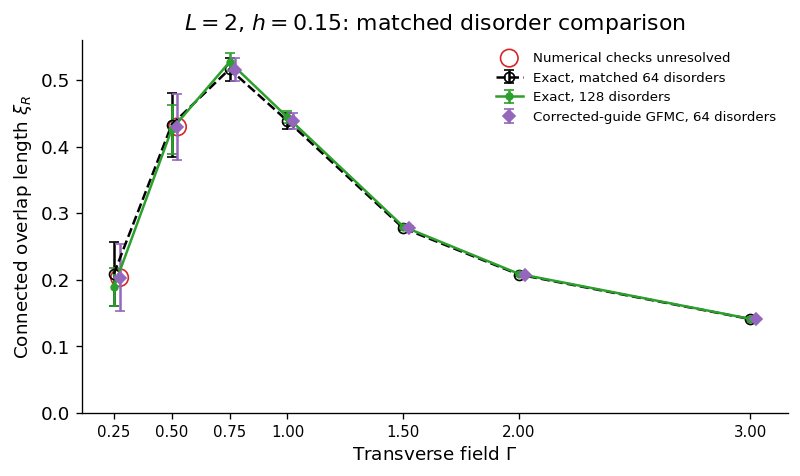

Γ,Exact ξ,GFMC ξ,GFMC − exact,Alarms /256,Check
0.250000,0.2085 ± 0.0481,0.2030 ± 0.0506,-0.0056 ± 0.0059,0,unresolved
0.500000,0.4327 ± 0.0484,0.4296 ± 0.0494,-0.0032 ± 0.0024,1,unresolved
0.750000,0.5165 ± 0.0173,0.5153 ± 0.0174,-0.0012 ± 0.0013,0,passes L2 ensemble and audit checks
1.000000,0.4386 ± 0.0121,0.4388 ± 0.0121,+0.0002 ± 0.0002,0,passes L2 ensemble and audit checks
1.500000,0.2774 ± 0.0031,0.2773 ± 0.0031,-0.0000 ± 0.0002,0,passes L2 ensemble and audit checks
2.000000,0.2076 ± 0.0016,0.2076 ± 0.0016,-0.0000 ± 0.0001,0,passes L2 ensemble and audit checks
3.000000,0.1406 ± 0.0010,0.1405 ± 0.0010,-0.0001 ± 0.0001,0,passes L2 ensemble and audit checks


In [2]:
if review:
    display(Markdown(f"**Downloaded and validated:** {review['completed_runs']}/{review['expected_runs']} runs; "
                     f"{review['complete_fields']}/7 complete 64-disorder fields."))
elif remote:
    progress=', '.join(f"{k}: {v.get('completed',0)}/{v.get('total',0)}"
                      for k,v in remote.items() if k in ('guides','production','audit'))
    display(Markdown('**Campaign in progress:** '+progress+'. GFMC points appear after complete groups are downloaded and validated.'))
else:
    display(Markdown('**GFMC campaign pending:** complete validated groups will populate all seven fields.'))
fig,ax=plt.subplots(figsize=(6.8,4.1))
ax.errorbar(exact.gamma,exact.exact,yerr=exact.exact_se,fmt='o--',color='black',
            markerfacecolor='none',capsize=3,ms=6,label='Exact, matched 64 disorders')
ax.errorbar(expanded.gamma,expanded.xi,yerr=expanded.bootstrap_se,fmt='o-',
            color='tab:green',capsize=3,ms=4,label='Exact, 128 disorders')
if len(measured):
    ax.errorbar(measured.gamma+.025,measured.gfmc,yerr=measured.gfmc_se,fmt='D',
                color='tab:purple',capsize=3,ms=5,label='Corrected-guide GFMC, 64 disorders')
    flagged=measured[~measured.checks_pass]
    if len(flagged):
        ax.scatter(flagged.gamma+.025,flagged.gfmc,facecolors='none',edgecolors='tab:red',s=110,
                   label='Numerical checks unresolved')
ax.set(xlabel=r'Transverse field $\Gamma$',ylabel=r'Connected overlap length $\xi_R$',
       title=r'$L=2$, $h=0.15$: matched disorder comparison',ylim=(0,None),xticks=FIELDS)
ax.tick_params(axis='x',labelsize=9);ax.legend(frameon=False,fontsize=8);fig.tight_layout()
save(fig,'length_exact_vs_gfmc')
if len(measured):
    display(pd.DataFrame({'Γ':measured.gamma,
        'Exact ξ':[f'{x:.4f} ± {s:.4f}' for x,s in zip(measured.exact,measured.exact_se)],
        'GFMC ξ':[f'{x:.4f} ± {s:.4f}' for x,s in zip(measured.gfmc,measured.gfmc_se)],
        'GFMC − exact':[f'{x:+.4f} ± {s:.4f}' for x,s in zip(measured.delta,measured.delta_se)],
        'Alarms /256':measured.ancestry_alarms,'Check':measured.comparison_status}).style.hide(axis='index'))

In [3]:
if review:
    display(Markdown(f"**Numerical assessment:** {review['ancestry_alarms']} ancestry alarms in "
        f"{review['completed_runs']} runs. Exact-spectrum and paired early/late checks use all "
        '64 disorders per field; population2048 and forward64/equilibration64 audits use '
        'eight prespecified disorders per field (50024–50031). Passing requires approximate '
        'pointwise 95% bounds within 0.01 for ξ/(2L) and 5% for every spectrum, with no ancestry alarms. '
        'All difficult disorders are retained. Four repeats limit tail resolution. '
        '[Full review](../data/kagome/ltfim_correlation_expanded_v1/VALIDATED_REVIEW.md).'))
    if review['complete_fields']==7:
        passed=[f"{r['gamma']:g}" for r in review['rows'] if r['checks_pass']]
        display(Markdown('**Passing fields:** Γ='+', '.join(passed)+'. '
            'At Γ=0.25, the eight-disorder audit retains roughly 14–21% spectral bias against exact results, '
            'despite stable population/time contrasts. At Γ=0.5, one production run has an ancestry alarm. '
            'Some low-field disorders also retain large individual spectral errors even when ancestry looks healthy; '
            'ensemble agreement can conceal cancellation. The low-field points remain unresolved and are retained in the plot. '
            'Passing refers to the ensemble and prespecified audit checks, not certification of every disorder.'))
display(Markdown(
    '**Scalability:** the present correction does not scale by enumeration. '
    'L=4 requires 2^48 states and 213,052 all-subset coefficients, versus 4,096 states and 793 coefficients at L=2. '
    'A separate sampled neural-refinement pilot ran at L=4 without enumeration, but lower energy did not '
    'establish accurate overlap spectra or converged GFMC. '
    '[Scalability assessment](../data/kagome/ltfim_correlation_expanded_v1/SCALABILITY.md).'))

**Numerical assessment:** 1 ancestry alarms in 2240 runs. Exact-spectrum and paired early/late checks use all 64 disorders per field; population2048 and forward64/equilibration64 audits use eight prespecified disorders per field (50024–50031). Passing requires approximate pointwise 95% bounds within 0.01 for ξ/(2L) and 5% for every spectrum, with no ancestry alarms. All difficult disorders are retained. Four repeats limit tail resolution. [Full review](../data/kagome/ltfim_correlation_expanded_v1/VALIDATED_REVIEW.md).

**Passing fields:** Γ=0.75, 1, 1.5, 2, 3. At Γ=0.25, the eight-disorder audit retains roughly 14–21% spectral bias against exact results, despite stable population/time contrasts. At Γ=0.5, one production run has an ancestry alarm. Some low-field disorders also retain large individual spectral errors even when ancestry looks healthy; ensemble agreement can conceal cancellation. The low-field points remain unresolved and are retained in the plot. Passing refers to the ensemble and prespecified audit checks, not certification of every disorder.

**Scalability:** the present correction does not scale by enumeration. L=4 requires 2^48 states and 213,052 all-subset coefficients, versus 4,096 states and 793 coefficients at L=2. A separate sampled neural-refinement pilot ran at L=4 without enumeration, but lower energy did not establish accurate overlap spectra or converged GFMC. [Scalability assessment](../data/kagome/ltfim_correlation_expanded_v1/SCALABILITY.md).

## 2. Correlation length versus size

Fix $\Gamma=0.5$, $h=0.15$. The $L=2$ benchmark uses the 64-disorder
protocol above. Existing $L=4$–10 measurements use 32 walkers,
equilibration0.04, forward0.04, branching0.02, two cycles, and one disorder
per size. **They are preliminary feasibility probes**, without defensible
error bars. Unresolved ratios are labelled; no physical scaling conclusion
follows from these data.

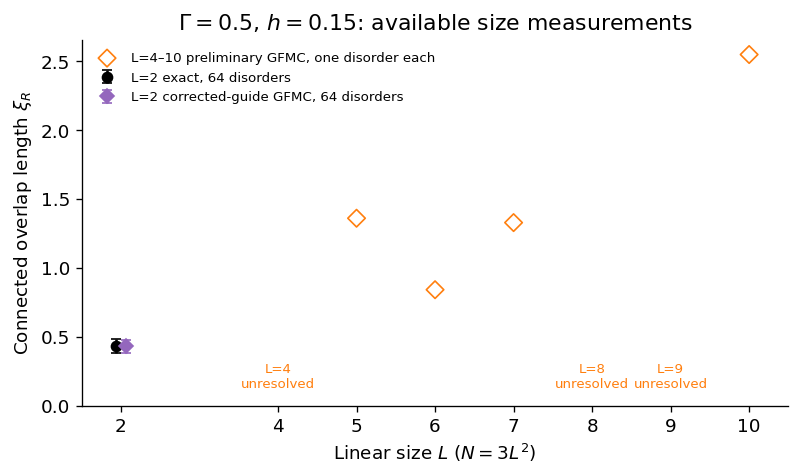

L,Preliminary GFMC ξ
4,unresolved
5,1.360
6,0.841
7,1.328
8,unresolved
9,unresolved
10,2.549


In [4]:
fig,ax=plt.subplots(figsize=(6.8,4.1))
anchor=exact[exact.gamma==.5].iloc[0]
ax.errorbar(2-.06,anchor.exact,yerr=anchor.exact_se,fmt='o',color='black',
            capsize=3,label='L=2 exact, 64 disorders')
if len(measured) and (measured.gamma==.5).any():
    anchor=measured[measured.gamma==.5].iloc[0]
    ax.errorbar(2+.06,anchor.gfmc,yerr=anchor.gfmc_se,fmt='D',color='tab:purple',
                capsize=3,label='L=2 corrected-guide GFMC, 64 disorders')
resolved=sizes[np.isfinite(sizes.xi)]
ax.scatter(resolved.L,resolved.xi,facecolors='none',edgecolors='tab:orange',marker='D',s=55,
           label='L=4–10 preliminary GFMC, one disorder each')
for L in sizes.loc[~np.isfinite(sizes.xi),'L']:
    ax.text(L,.04,f'L={L}\nunresolved',transform=ax.get_xaxis_transform(),ha='center',
            va='bottom',color='tab:orange',fontsize=8)
ax.set(xlabel=r'Linear size $L$ ($N=3L^2$)',ylabel=r'Connected overlap length $\xi_R$',
       title=r'$\Gamma=0.5$, $h=0.15$: available size measurements',
       xticks=[2,4,5,6,7,8,9,10],xlim=(1.5,10.5),ylim=(0,None))
ax.legend(frameon=False,fontsize=8);fig.tight_layout();save(fig,'length_versus_L')
display(pd.DataFrame({'L':sizes.L,'Preliminary GFMC ξ':[
    f'{x:.3f}' if np.isfinite(x) else 'unresolved' for x in sizes.xi]}).style.hide(axis='index'))

## Interpreting size dependence

A finite nonzero $\xi_R$ does not establish a spin glass.

The matched exact curve has its largest sampled value near $\Gamma=0.75$,
with $\xi_R\simeq0.516$ and $\xi_R/(2L)\simeq0.129$ at $L=2$.
This supports an intermediate-field enhancement of connected correlations
on this small lattice. The precise peak location is less certain: a paired
disorder bootstrap for exact $\xi_R(0.75)-\xi_R(0.5)$ gives a 95% interval
of approximately $[-0.006,0.190]$ (64 disorders, 10,000 draws).
The existing larger-size probes cannot establish growth with $L$.

| Large-$L$ behavior | Interpretation |
|---|---|
| $\xi_R\to\xi_\infty>0$, finite | Short-range correlations; $\xi_R/(2L)\to0$. |
| $\xi_R$ grows over accessible sizes | Growing correlation range; eventual saturation still needs testing. |
| $\xi_R/(2L)$ tends to a nonzero value | Correlations span a finite fraction of the system. |

Growth can also accompany conventional order or criticality. Check magnetic
order alongside overlap scaling. This length measures **connected fluctuations**;
a field-selected frozen state may still have short-range connected fluctuations.
Neither a large overlap nor a finite connected length alone classifies frozen order.

[Campaign data and validation](../data/kagome/ltfim_correlation_expanded_v1/).
Rebuilding reads cached data and validates identities; it launches no simulations.